# Fitness landscape characterization and analysis of no antibody simulations
## Generates Fig. 1, Fig. S1, Fig. S8, Fig. S9

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgb
import networkx as nx
from scipy.spatial.distance import pdist, squareform
import seaborn as sns
import glob
import re

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.frameon": False,
    "legend.fontsize": 'small',
    "figure.dpi": 600,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

params = {
    "lambda_T": 1e7,
    "d": 0.2,

    #Infection dynamics
    "beta_wt": 2e-9,
    "gamma": 1.0,
    "delta1": 0.5,
    "delta2": 1.0,
    "n": 1000.0,
    "c": 20.0,

    #Binding affinity
    "RT": 0.616,
    "KD_WT": 1e-8,
    "h": 0.1,
    "K": 5,

    #Antibody dynamics
    "k": 0.664,
    "a1": 0.288,
    "a2": 0.070
}

color_all = '#054fb9'
color_peaks = '#C44601'

## Use EvoEF-predicted ddG values to construct the fitness landscape and shuffles the observed ddG distribution to find the number of peaks on shuffled landscapes 

In [2]:
rng = np.random.default_rng(1)

#Load ddG and map to sequence indices
ddG_dataframe = pd.read_csv('../EvoEF_predictions/predictions_WT_Ab.csv', index_col=0)

AA_ALPHABET = list("ACDEFGHIKLMNPQRSTVWY")
aa2idx = {aa:i for i,aa in enumerate(AA_ALPHABET)}

base = np.array([20**i for i in range(5)], dtype=np.int64)
indices = (ddG_dataframe.iloc[:,0].map(aa2idx).to_numpy() * base[0] +
           ddG_dataframe.iloc[:,1].map(aa2idx).to_numpy() * base[1] +
           ddG_dataframe.iloc[:,2].map(aa2idx).to_numpy() * base[2] +
           ddG_dataframe.iloc[:,3].map(aa2idx).to_numpy() * base[3] +
           ddG_dataframe.iloc[:,4].map(aa2idx).to_numpy() * base[4])

ddg_array = np.empty(20**5, dtype=float)
ddg_array[indices] = ddG_dataframe['ddG'].to_numpy()

#Identify fitness peaks
def identify_peaks(ddg_vec):
    L = 5
    N = ddg_vec.size
    found_peaks = []
    for i in range(N):
        current_ddg = ddg_vec[i]
        is_peak = True

        #Loop through all single AA mutations at each position and check if any have higher fitness
        for pos in range(L):
            curr_aa = (i // base[pos]) % 20
            for a in range(20):
                if a == curr_aa:
                    continue
                neighbor = i + (a - curr_aa) * base[pos]
                if ddg_vec[neighbor] < current_ddg:
                    is_peak = False
                    break
            if not is_peak:
                break
        if is_peak:
            found_peaks.append(i)
    return found_peaks

peaks = identify_peaks(ddg_array)
peak_ddg = ddg_array[peaks]

#Find Hamming distance between peaks
def codes_to_digits(codes, base):
    codes = np.asarray(codes, dtype=np.int64)
    M = codes.shape[0]
    digits = np.empty((M, 5), dtype=np.int8)
    for pos in range(5):
        digits[:, pos] = ((codes // base[pos]) % 20).astype(np.int8)
    return digits

peak_digits = codes_to_digits(peaks, base)
hdist_peaks = (pdist(peak_digits, metric='hamming')*5).astype(int)

#Find Hamming distance between randomly selected sequences
rand_codes = rng.choice(np.arange(20**5), size=len(peaks), replace=False)
rand_digits = codes_to_digits(rand_codes, base)
hdist_rand = (pdist(rand_digits, metric='hamming')*5).astype(int)

#Shuffle ddG landscape 100 times and determine the number of peaks on each shuffled landscapes
n_shuffles = 100
shuffle_counts = []

for s in range(n_shuffles):
    perm_indices = rng.permutation(20**5)
    perm_ddg = ddg_array[perm_indices]
    peaks_perm = identify_peaks(perm_ddg)
    shuffle_counts.append(len(peaks_perm))
shuffle_counts = np.array(shuffle_counts, dtype=int)

## Generate Fig. S8: distribution of the number of peaks on 100 shuffled landscapes

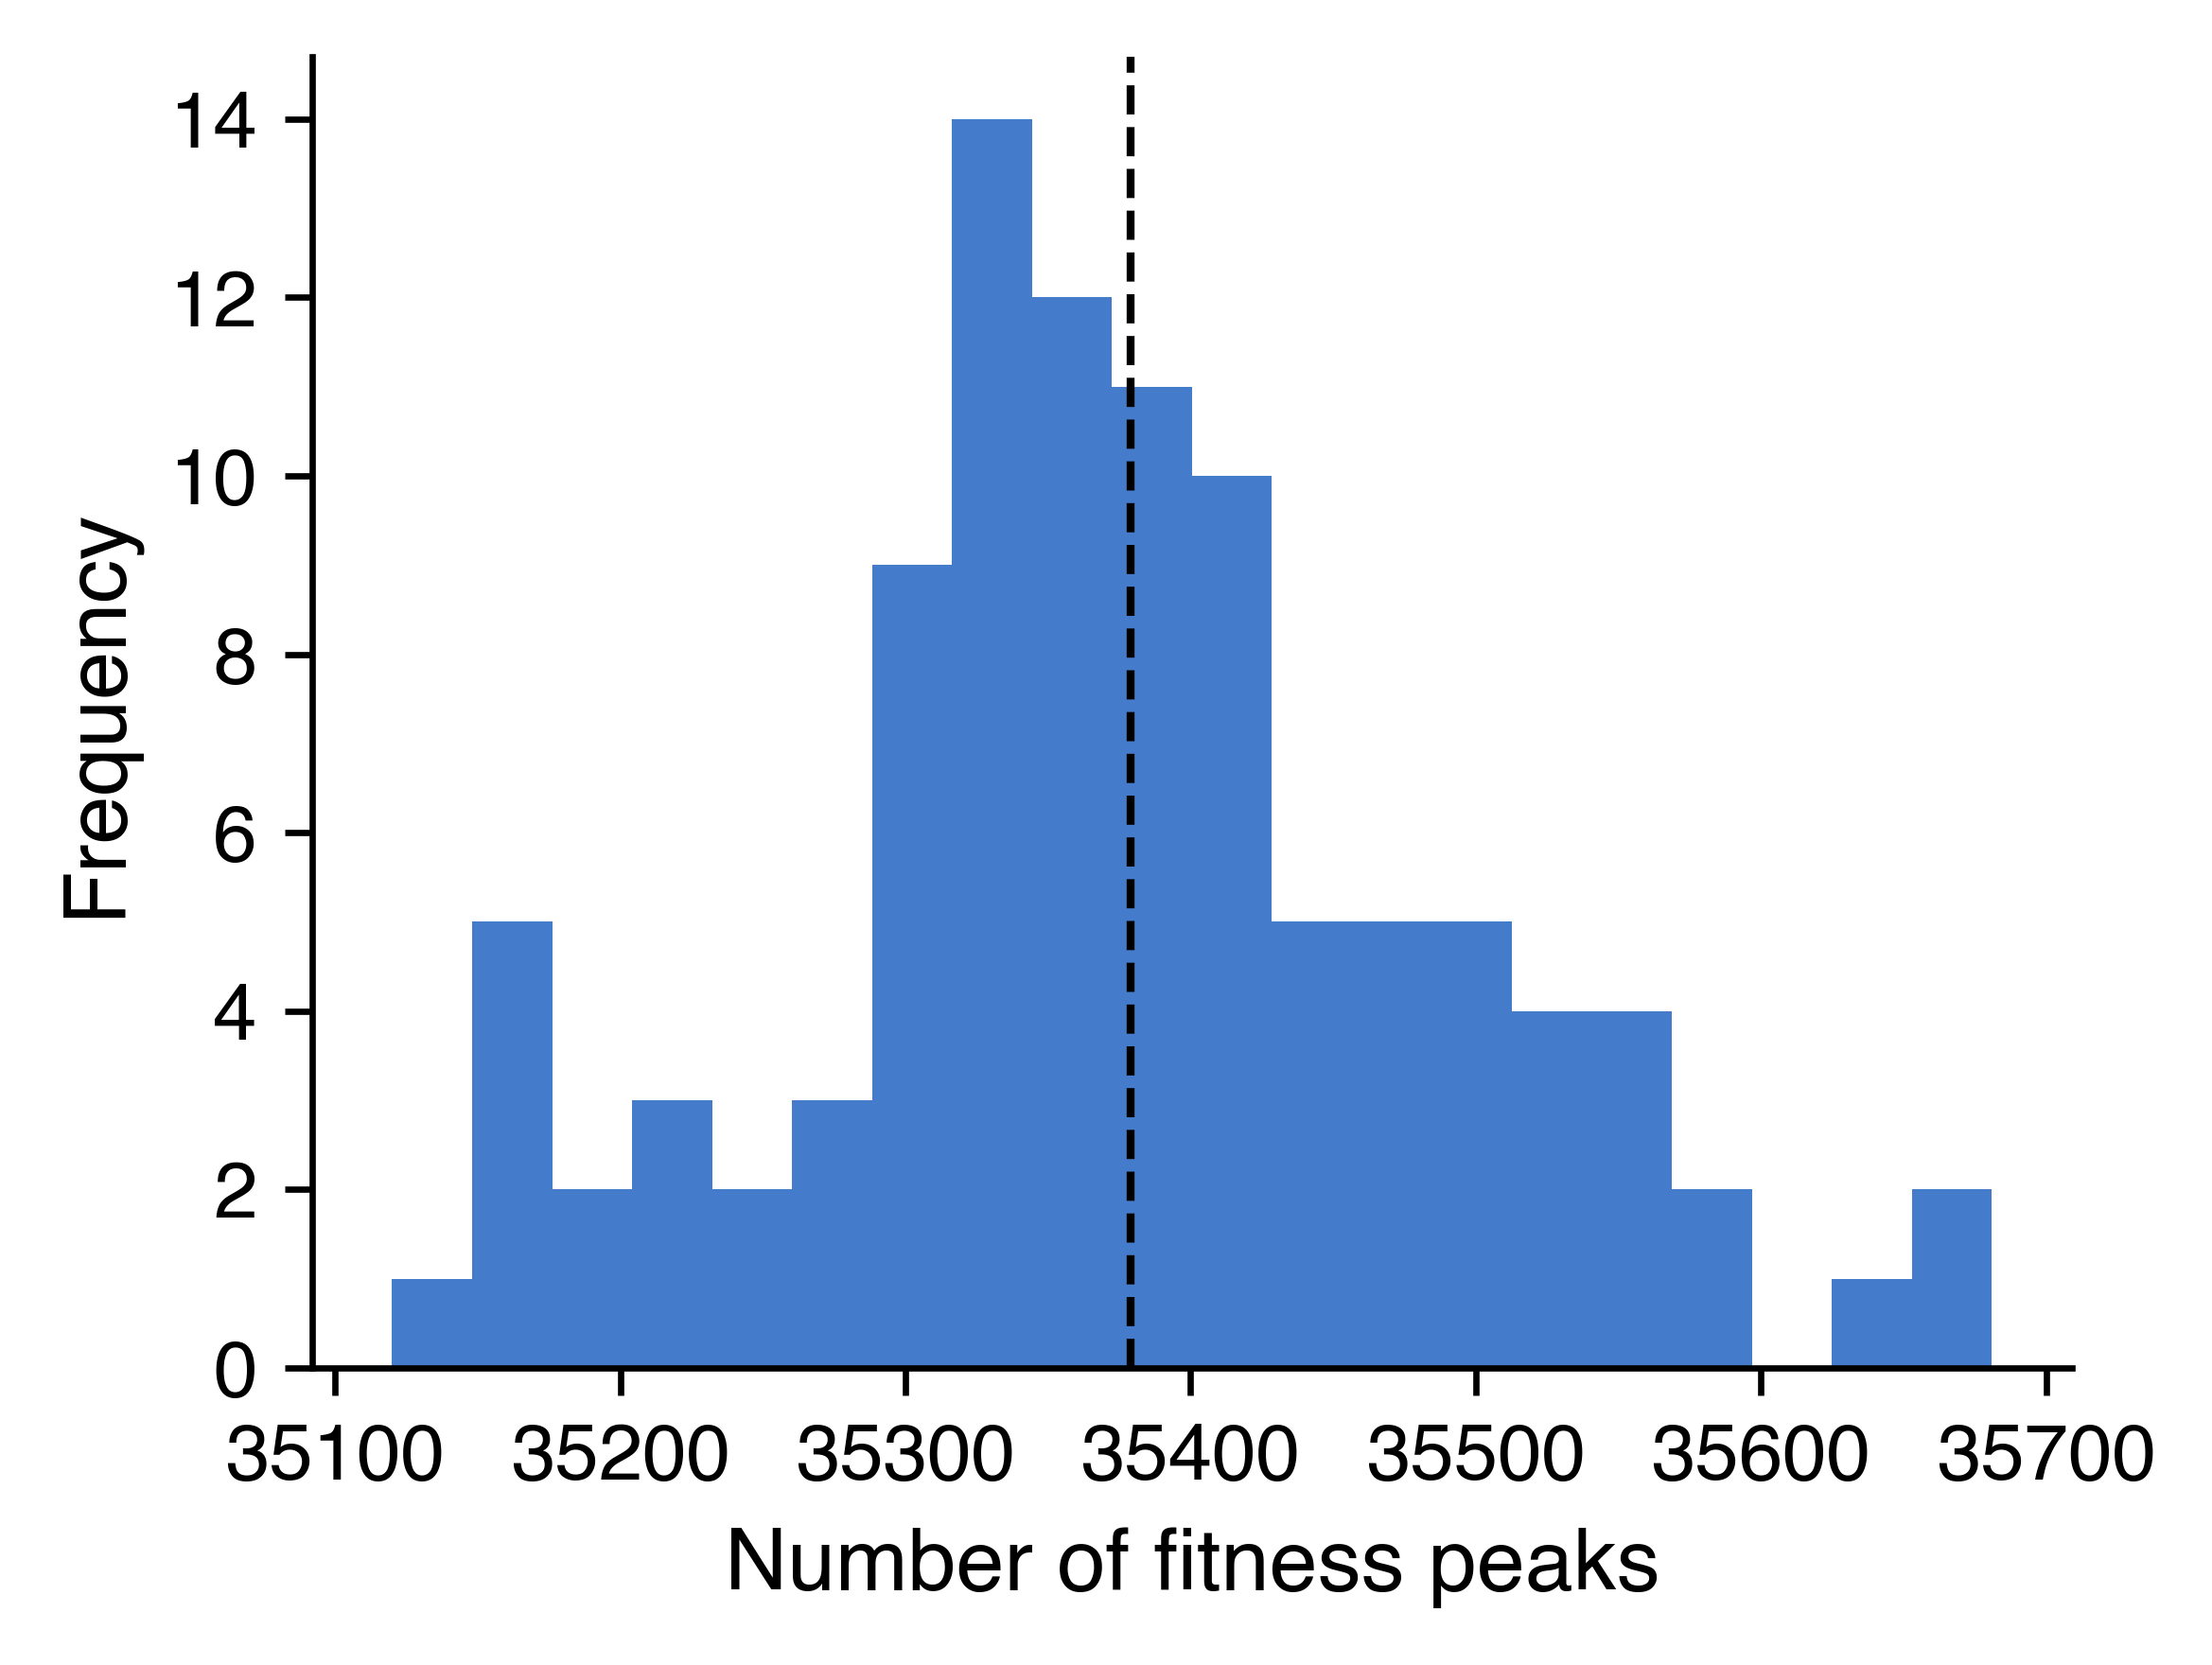

In [3]:
fig = plt.figure(figsize=(4, 3), constrained_layout=False)
plt.hist(shuffle_counts, bins=20, color=color_all, alpha=0.75)
plt.axvline(np.mean(shuffle_counts), linestyle='--', color='k', linewidth=1)
plt.xlabel('Number of fitness peaks')
plt.ylabel('Frequency')
plt.savefig('FigS8.png', dpi=600, bbox_inches='tight')

## Find neutral networks in the computed landscape and characterize their mutational neighborhoods

In [4]:
#Find connected components in the peak graph
adj = (squareform(hdist_peaks) == 1).astype(int)
G = nx.from_numpy_array(adj)
components = list(nx.connected_components(G))
network_id = np.zeros(len(peaks), dtype=int)
for i, comp in enumerate(components):
    network_id[list(comp)] = i

#Calculate fraction of neutral neighbors and change in ddG for point mutations for each peak
n_peaks = len(peaks)
avg_neighbor_ddg = np.empty(n_peaks, dtype=float)
frac_neutral_neighbors = np.empty(n_peaks, dtype=float)
avg_nonneutral_neighbor_ddg = np.empty(n_peaks, dtype=float) 
count_nonneutral = np.zeros(n_peaks, dtype=int)

for i, code in enumerate(peaks):
    self_ddg = ddg_array[code]
    dig = ((code // base) % 20)
    neighbors = []
    for pos in range(5):
        curr_aa = dig[pos]
        for a in range(20):
            if a == curr_aa:
                continue
            neighbor = int(code + (a - curr_aa) * base[pos])
            neighbors.append(neighbor)
    neighbors = np.array(neighbors, dtype=int)
    vals = ddg_array[neighbors]

    #Record statistics
    frac_neutral_neighbors[i] = np.mean(vals == self_ddg)
    avg_neighbor_ddg[i] = np.mean(vals) - self_ddg
    nonneutral_mask = vals != self_ddg
    count_nonneutral[i] = nonneutral_mask.sum()
    avg_nonneutral_neighbor_ddg[i] = np.mean(vals[nonneutral_mask]) - self_ddg

seqs = ["".join([AA_ALPHABET[int((c // base[pos]) % 20)] for pos in range(5)]) for c in peaks]

neutral_network_data = pd.DataFrame({
    "node": np.arange(len(peaks)),
    "component": network_id,
    "sequence": seqs,
    "avg_neighbor_ddg": avg_neighbor_ddg,
    "frac_neutral_neighbors": frac_neutral_neighbors,
    "avg_nonneutral_neighbor_ddg": avg_nonneutral_neighbor_ddg,
    "count_nonneutral": count_nonneutral
})

network_stats = [(round(peak_ddg[neutral_network_data[neutral_network_data['component']==i]['node']][0],2),len(neutral_network_data[neutral_network_data['component']==i])) for i in range(4)]
network_labels = [f"$\Delta\Delta$G = {network_stats[i][0]}\nn = {network_stats[i][1]}" for i in range(4)]
nl = [x for _, x in sorted(zip(network_stats, network_labels), key=lambda t: t[0][0])]
order = [i for i, _ in sorted(enumerate(network_stats), key=lambda t: t[1][0])]

## Generate Fig. S9: mutational neighborhood characterization (fraction of neutral neighbors and average change in binding affinity)

/var/folders/kn/lt_mw8_s7w13q8_sljnxpprm0000gn/T/ipykernel_10546/2620358896.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_top1.set_yticklabels(nl)


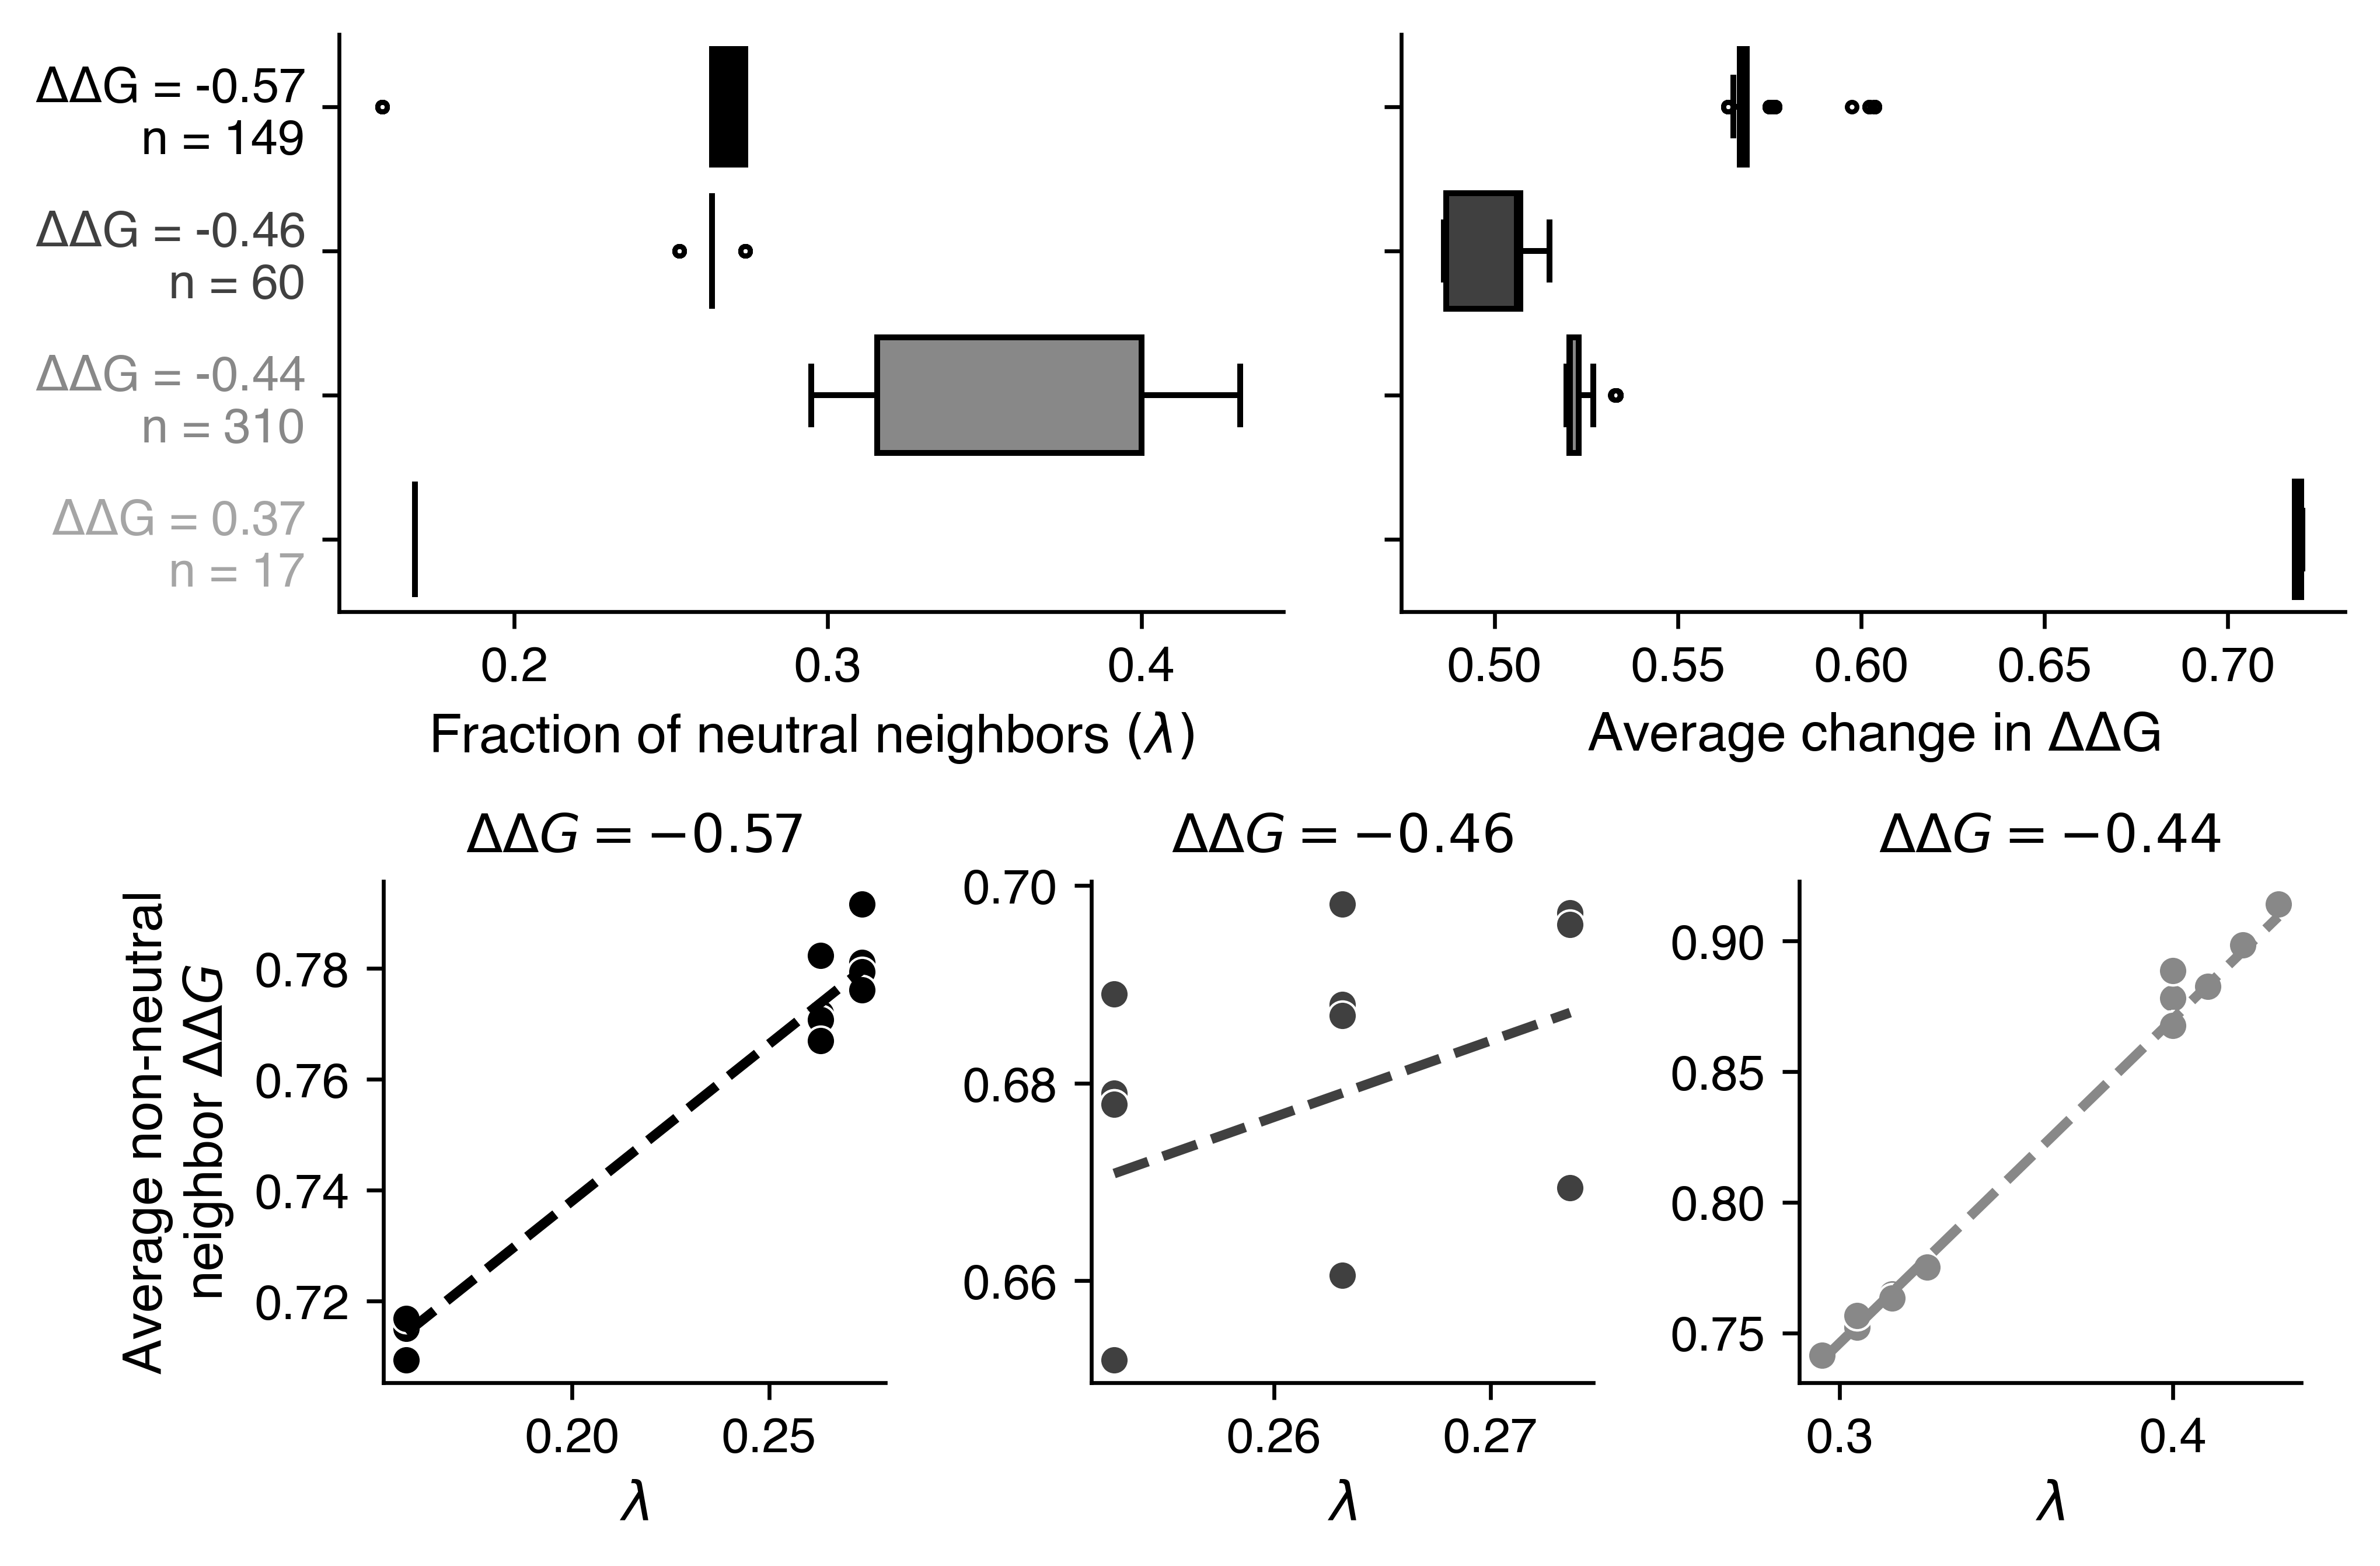

In [5]:
palette = plt.cm.Greys_r([0, 0.2, 0.45, 0.55])
palette_dict = {comp: palette[rank] for rank, comp in enumerate(order)}
fig = plt.figure(figsize=(10, 5), constrained_layout=False)
gs = fig.add_gridspec(2, 8, height_ratios=[1.15, 1], hspace=0.5, wspace=0.5)

ax_top1 = fig.add_subplot(gs[0, 1:4])
ax_top2 = fig.add_subplot(gs[0, 4:7])
ax_bot1 = fig.add_subplot(gs[1, 1:3])
ax_bot2 = fig.add_subplot(gs[1, 3:5])
ax_bot3 = fig.add_subplot(gs[1, 5:7])

for ax in [ax_bot1, ax_bot2, ax_bot3]:
    ax.set_box_aspect(1)

sns.boxplot(
    data=neutral_network_data,
    x='frac_neutral_neighbors',
    y='component',
    hue='component',
    order=order,
    hue_order=order,
    palette=palette_dict,
    dodge=False,
    orient='h',
    linewidth=1.2,
    fliersize=2,
    ax=ax_top1
)
ax_top1.legend_.remove()
ax_top1.set_xlabel(r"Fraction of neutral neighbors $(\lambda)$")
ax_top1.set_ylabel("")
ax_top1.set_yticklabels(nl)

sns.boxplot(
    data=neutral_network_data,
    x='avg_neighbor_ddg',
    y='component',
    hue='component',
    order=order,
    hue_order=order,
    palette=palette_dict,
    dodge=False,
    orient='h',
    linewidth=1.2,
    fliersize=2,
    ax=ax_top2
)
ax_top2.legend_.remove()
ax_top2.set_xlabel(r"Average change in $\Delta\Delta$G")
ax_top2.set_ylabel("")
ax_top2.set_yticklabels([])

for ax in [ax_top1, ax_top2]:
    for tick, color in zip(ax.get_yticklabels(), palette):
        tick.set_color(color)
        tick.set_fontweight('bold')

networks = [0, 3, 2]
bottom_axes = [ax_bot1, ax_bot2, ax_bot3]

for i, (n, ax) in enumerate(zip(networks, bottom_axes)):
    sub = neutral_network_data[neutral_network_data['component'] == n]

    color = palette_dict[n]
    x = sub['frac_neutral_neighbors'].to_numpy()
    y = sub['avg_nonneutral_neighbor_ddg'].to_numpy()

    ax.scatter(x, y, s=35, color=color, edgecolor='white', linewidth=0.5)
    ddg = peak_ddg[sub['node'].iloc[0]]
    ax.set_title(rf'$\Delta\Delta G={ddg:.2f}$')

    ax.set_xlabel(r'$\lambda$')
    if i == 0:
        ax.set_ylabel(f'Average non-neutral\nneighbor $\Delta\Delta G$')
    else:
        ax.set_ylabel("")

    #Regression line
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, slope * xs + intercept, linestyle='--', color=color, linewidth=2)
    
plt.savefig('FigS9.png', dpi=600, bbox_inches='tight')

## Parsing scripts for simulations

In [6]:
def seed_from_fname(fname):
    m = re.search(r"seed(\d+)", fname)
    return int(m.group(1)) if m else None

def read_totals(path, common_times):
    td = (pd.read_csv(path).set_index("time").reindex(common_times).fillna(0.0))
    return td["T"].to_numpy(float), td["sum_V"].to_numpy(float)

def read_topk(path, common_times):
    kd = pd.read_csv(path)
    grouped = kd.groupby(["sequence", "time"], as_index=False)["V"].sum()
    pivot = grouped.pivot(index="sequence", columns="time", values="V").fillna(0.0)
    return pivot.reindex(columns=common_times, fill_value=0.0)

def shannon_effective_species(v, total):
    if total <= 0 or v.sum() == 0:
        return 0.0
    freqs = v / total
    H = -np.sum(freqs[freqs > 0] * np.log(freqs[freqs > 0]))
    return float(np.exp(H))

def summarize(arr):
    return arr.mean(axis=0), arr.min(axis=0), arr.max(axis=0)

base_dir = "../Simulation_data/No_Ab/sim_outputs"
totals_files = sorted(glob.glob(f"{base_dir}/totals_noAb_seed*.csv"))
topk_files = sorted(glob.glob(f"{base_dir}/topk_noAb_seed*.csv"))

totals_by_seed = {seed_from_fname(f): f for f in totals_files}
topk_by_seed = {seed_from_fname(f): f for f in topk_files}
seeds = sorted(set(totals_by_seed) & set(topk_by_seed))

ex = pd.read_csv(totals_by_seed[seeds[0]])
common_times = np.sort(ex["time"].unique())
n_times = len(common_times)
n_seeds = len(seeds)
T_stack = np.zeros((n_seeds, n_times))
V_stack = np.zeros((n_seeds, n_times))
D_stack = np.zeros((n_seeds, n_times))

for i, s in enumerate(seeds):
    totals_path = totals_by_seed[s]
    topk_path = topk_by_seed[s]

    T_arr, sumV_arr = read_totals(totals_path, common_times)
    pivot = read_topk(topk_path, common_times)

    D_arr = np.array([shannon_effective_species(pivot.iloc[:, ti].to_numpy(), sumV_arr[ti]) for ti in range(n_times)])

    T_stack[i] = T_arr
    V_stack[i] = sumV_arr
    D_stack[i] = D_arr

T_mean, T_min, T_max = summarize(T_stack)
V_mean, V_min, V_max = summarize(V_stack)
D_mean, D_min, D_max = summarize(D_stack)

## Core/accessory/unique variant classification and abundance analysis

In [7]:
def _integrated_V(topk_df):
    grp = topk_df.groupby(["sequence", "time"], as_index=False)["V"].sum()
    pivot = grp.pivot_table(index="sequence", columns="time", values="V", aggfunc="sum", fill_value=0.0)
    times = np.sort(pivot.columns.astype(float))
    pivot = pivot.reindex(columns=times, fill_value=0.0)
    areas = np.trapezoid(pivot.to_numpy(float), x=times, axis=1)
    return dict(zip(pivot.index, areas))

def compute_global_topk(topk_dfs, top_k=20):
    """Compute the global top-K sequences across runs by summing integrated viral loads per variant."""
    
    totals = {}
    for df in topk_dfs:
        for seq, area in _integrated_V(df).items():
            totals[seq] = totals.get(seq, 0.0) + area
    return [s for s, _ in sorted(totals.items(), key=lambda x: x[1], reverse=True)[:top_k]]

def single_topk_set(topk_df, top_k=20):
    """Get the top-K sequences from a single simulation run."""
    
    areas = _integrated_V(topk_df)
    return set(sorted(areas, key=areas.__getitem__, reverse=True)[:top_k])

def classify_sequences(topk_dfs, global_seqs, top_k=20, threshold_acc=0.5):
    """Classify each sequence in the global top K as core/accessory/unique
    based on how often they appear in the top K of each individual simulation."""

    n_runs = len(topk_dfs)
    counts = {s: 0 for s in global_seqs}

    for df in topk_dfs:
        run_topk = single_topk_set(df, top_k)
        for s in run_topk:
            if s in counts:
                counts[s] += 1

    labels = {}
    for s, cnt in counts.items():
        frac = cnt / n_runs
        if frac == 1.0:
            labels[s] = "core"
        elif frac >= threshold_acc:
            labels[s] = "accessory"
        else:
            labels[s] = "unique"

    return labels

def r0_fun(ddg_receptor, ddg_ab, Ab_dose, p):
    ddg_receptor = np.asarray(ddg_receptor, dtype=float)
    mult = (1.0+p['h'])**p['K']
    ddg_receptor_transform = mult*(1.0/(1.0 + p['h']*np.exp(ddg_receptor / p['RT']))) ** p['K']
    ddg_ab = np.asarray(ddg_ab, dtype=float)
    Ab_dose = np.asarray(Ab_dose, dtype=float)
    return (p['beta_wt']*ddg_receptor_transform*p['lambda_T']*p['gamma']*p['n'])/(p['c']*p['d']*(p['delta1']+p['gamma'])*(1+((Ab_dose/p['KD_WT'])*np.exp(-ddg_ab/p['RT']))))

In [8]:
def build_color_map(global_seqs, wt_seq='DIRQH', wt_slot=0, palette="tab20"):
    """Build a sequence -> color mapping for a set of viral sequences.
    Give the wild type a specific color in the palette."""
    tab20 = sns.color_palette(palette, 20)
    wt_rgb = to_rgb(tab20[wt_slot % 20])
    pool = [to_rgb(c) for i, c in enumerate(tab20) if i != wt_slot % 20]

    cmap: dict = {}
    if wt_seq in global_seqs:
        cmap[wt_seq] = wt_rgb

    pi = 0
    for s in global_seqs:
        if s not in cmap:
            cmap[s] = pool[pi % len(pool)]
            pi += 1

    cmap["__others__"] = "#ebebebf2"
    return cmap

def _build_pivot(topk_df, times):
    grp = topk_df.groupby(["sequence", "time"], as_index=False)["V"].sum()
    pivot = grp.pivot_table(index="sequence", columns="time", values="V", aggfunc="sum", fill_value=0.0)
    return pivot.reindex(columns=times, fill_value=0.0)

def _freq_matrix(pivot, sequences, totals_ts):
    rows = [pivot.loc[s].to_numpy(float) if s in pivot.index else np.zeros(pivot.shape[1]) for s in sequences]
    arr = np.vstack(rows) if rows else np.zeros((1, pivot.shape[1]))

    with np.errstate(divide="ignore", invalid="ignore"):
        freqs = np.divide(arr, totals_ts[np.newaxis, :], where=totals_ts > 0)
        freqs[:, totals_ts == 0] = 0.0

    others = np.clip(1.0 - freqs.sum(axis=0), 0.0, 1.0)
    return np.vstack([freqs, others])

def _shade_below_vl(ax, times, totals_ts, threshold=1, color="#4a4a4a", y_top=1.0, y_bottom=-1.0):
    low = totals_ts < threshold
    if not low.any():
        return
    pad = np.r_[0, low.view(np.int8), 0]
    diffs = np.diff(pad)
    for s_idx, e_idx in zip(np.where(diffs == 1)[0], np.where(diffs == -1)[0]):
        t_seg = times[s_idx - 1: e_idx]
        if t_seg.size:
            ax.fill_between(t_seg, y_bottom, y_top, color=color, alpha=1.0,
                            linewidth=0, zorder=10)

def stacked_frequency_plot(ax, totals_df, topk_df, sequences, color_map, classification=None,
                            x_max=365, wt_seq='DIRQH', vl_mode=False, wt_legend=False, y_floor=-1):
    """Plot the frequencies of the top-K variants over time in a simulation.
    Optionally takes in a variant classification for labeling core/accessory/unique variants from multiple simulations.
    If vl_mode=TRUE, the VL curve is plotted and abundances on a log scale are shown underneath this curve."""
    times = np.sort(totals_df["time"].unique())
    totals_ts = totals_df.set_index("time").reindex(times)["sum_V"].fillna(0.0).to_numpy(float)
    n_seqs = len(sequences)
    pivot = _build_pivot(topk_df, times)
    freq_mat = _freq_matrix(pivot, sequences, totals_ts)

    if vl_mode:
        log_vl = np.where(totals_ts > 0, np.log10(totals_ts / 5000), np.nan)
        above_threshold = totals_ts >= 0.01
        log_vl_clipped = np.where(above_threshold, log_vl, np.nan)
        span = log_vl_clipped - y_floor
        weights = np.where(span > 0, span, np.nan)
        y_max = np.log10(3e5)
    else:
        weights = np.ones(len(times))
        y_max = 1.0

    stack = freq_mat * weights[np.newaxis, :]
    cum = np.nancumsum(stack, axis=0) if vl_mode else np.cumsum(stack, axis=0)
    base = y_floor if vl_mode else 0.0
    bottoms = np.vstack([np.full(len(times), base), base + cum[:-1]])

    def _bot_top(i):
        return bottoms[i], bottoms[i] + stack[i]

    labels = sequences + ["__others__"]
    for i, lbl in enumerate(labels):
        color = color_map.get(lbl, color_map["__others__"])
        bot_i, top_i = _bot_top(i)
        ax.fill_between(times, bot_i, top_i, facecolor=color, linewidth=0)
        #Hatching for accessory/unique sequences
        if i < n_seqs and classification and lbl in classification:
            cat = classification[lbl]
            hatch = ("////" if cat == "accessory" else "xxxx" if cat == "unique" else None)
            if hatch:
                ax.fill_between(times, bot_i, top_i, facecolor="none", edgecolor="white", linewidth=0, hatch=hatch, alpha=0.5)

    _shade_below_vl(ax, times, totals_ts, y_top=y_max)
    ax.set_xlim(times.min(), x_max)

    if vl_mode:
        ax.plot(times, log_vl, color="black", lw=1.5, zorder=8)
        y_ceil = int(np.ceil(y_max))
        ticks = list(range(y_floor, y_ceil + 1))
        ax.set_yticks(ticks)
        ax.set_yticklabels([f"$10^{{{t}}}$" for t in ticks])
        ax.set_ylim(y_floor, y_max)
        ax.set_ylabel("Viral Load (mL$^{-1}$)")
    else:
        ax.set_ylim(0, 1)
        ax.set_ylabel("Frequency")

    if wt_legend and wt_seq in sequences:
        ax.legend(handles=[mpatches.Patch(color=color_map[wt_seq], label=f"Wild type ({wt_seq})")], bbox_to_anchor=(0.5, 1.18), loc="upper center", frameon=False)

## Generate Fig. 1: landscape characterization and no antibody simulations

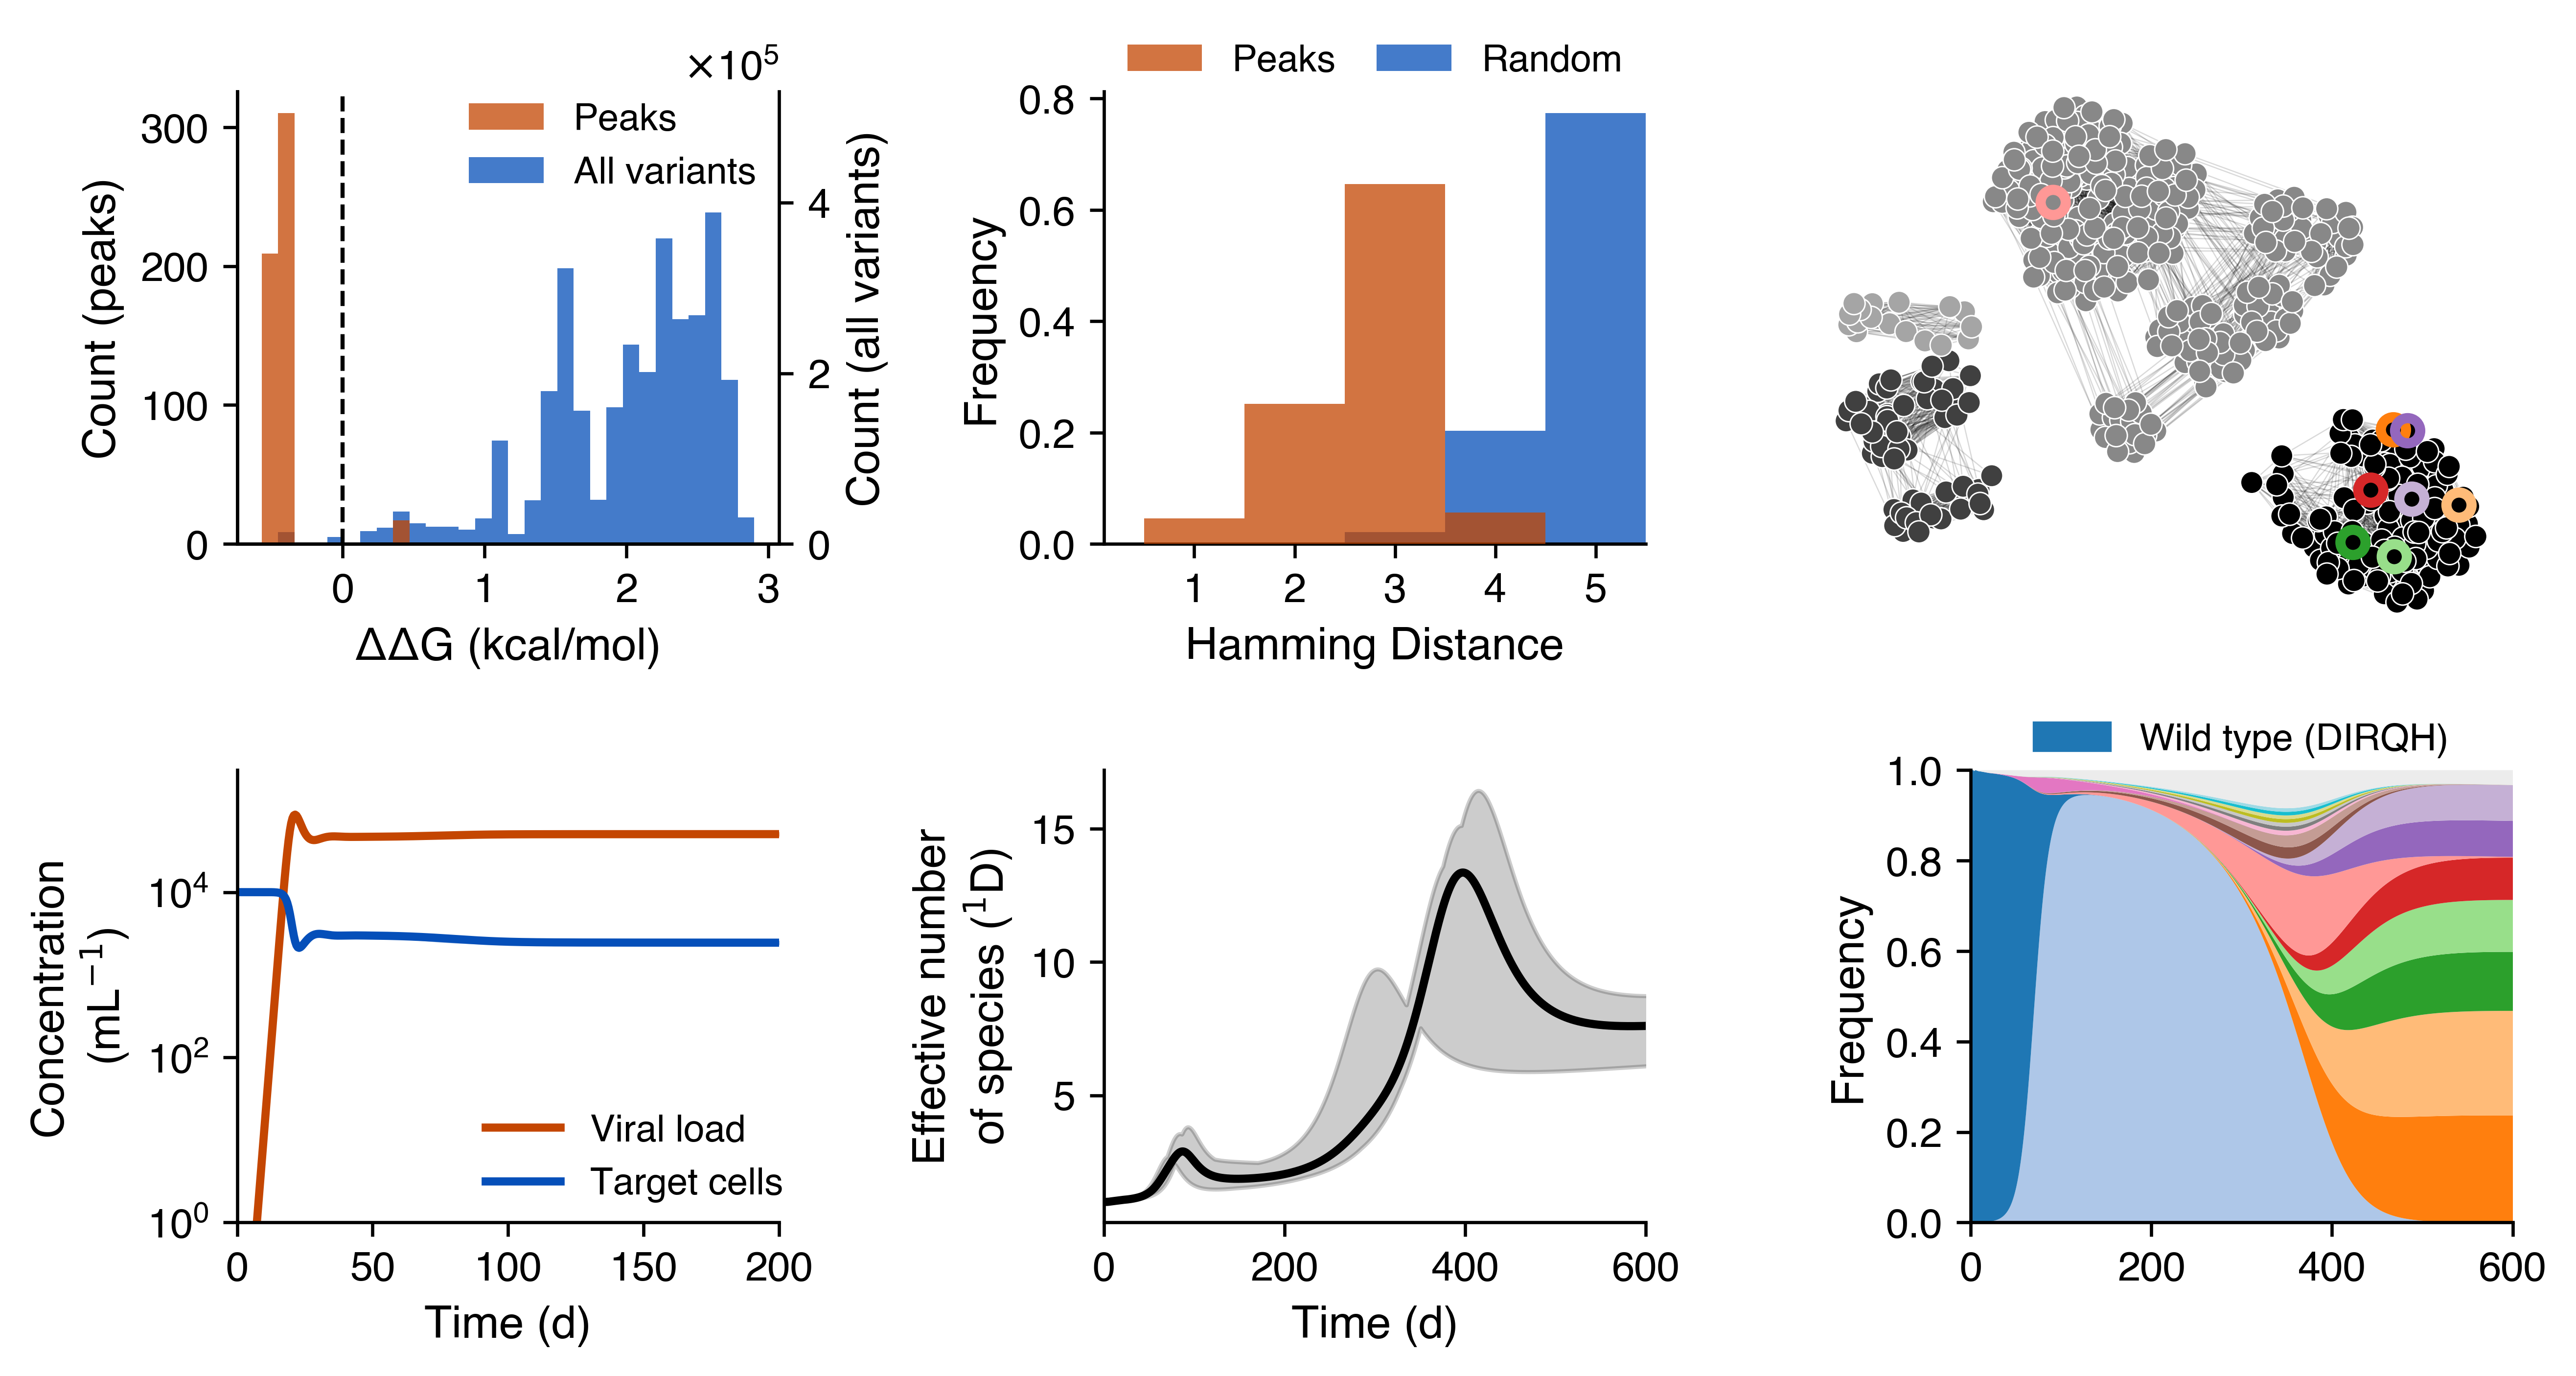

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5), constrained_layout=False)
axes = axes.flatten()
fig.subplots_adjust(wspace=0.6, hspace=0.5)

#Panel 1a
bin_edges = np.histogram_bin_edges(ddg_array, bins=30)
axes0_2 = axes[0].twinx()
n_all, bins_all, patches_all = axes0_2.hist(ddg_array, bins=bin_edges, color=color_all, alpha=0.75, label="All variants")
n_peaks, bins_peaks, patches_peaks = axes[0].hist(peak_ddg, bins=bin_edges, color=color_peaks, alpha=0.75, label="Peaks")
axes[0].axvline(0, linestyle='--', color='k', linewidth=1)
axes[0].set_xlabel("ΔΔG (kcal/mol)")
axes[0].set_ylabel("Count (peaks)")
axes0_2.set_ylabel("Count (all variants)")
axes0_2.set_ylim([0, 5.3*10**5])
axes[0].set_zorder(axes0_2.get_zorder() + 1)
axes[0].patch.set_visible(False)
axes0_2.yaxis.set_major_formatter(mticker.ScalarFormatter(useMathText=True))
axes0_2.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
lines, labels = axes[0].get_legend_handles_labels()
lines2, labels2 = axes0_2.get_legend_handles_labels()
axes0_2.legend(lines + lines2, labels + labels2, loc='upper right', bbox_to_anchor=(1.02, 1.05))
axes0_2.spines['right'].set_visible(True)

#Panel 1b
bins = np.arange(-0.5, 5+1.5, 1)
axes[1].hist(hdist_peaks, bins=bins, alpha=0.75, density=True, label='Peaks', color=color_peaks, zorder=10)
axes[1].hist(hdist_rand, bins=bins, alpha=0.75, density=True, label='Random', color=color_all, zorder=1)
axes[1].set_xlabel('Hamming Distance')
axes[1].set_ylabel('Frequency')
axes[1].legend(bbox_to_anchor=(0.5, 1.18), ncol=2, columnspacing=1.1, loc='upper center')
axes[1].set_xticks([1, 2, 3, 4, 5])
axes[1].set_xlim([0.1, 5.5])

#Panel 1c
#Get top 20 sequences in a simulation run and build a color map
example_totals = pd.read_csv(base_dir+'/totals_noAb_seed8.csv')
example_topk = pd.read_csv(base_dir+'/topk_noAb_seed8.csv')
topk_seqs = compute_global_topk([example_topk])
ex_colmap = build_color_map(topk_seqs)

#Neutral network graph
pos = axes[2].get_position()
axes[2].set_position([
    pos.x0 - 0.065,
    pos.y0 - 0.075,
    pos.width + 0.075,
    pos.height + 0.1
])
component_ddg = np.array([
    peak_ddg[np.where(network_id == i)[0][0]]
    for i in range(len(components))
])
order = np.argsort(component_ddg)
palette = plt.cm.Greys_r([0, 0.2, 0.45, 0.55])

component_colors = np.empty((4, 4))
for rank, comp in enumerate(order):
    component_colors[comp] = palette[rank]

node_colors = [component_colors[network_id[n]] for n in range(len(peaks))]

pos = nx.spring_layout(G, seed=4, iterations=400, k=2)
pos_arr = np.array(list(pos.values()))
xmin, ymin = pos_arr.min(axis=0)
xmax, ymax = pos_arr.max(axis=0)
for n in pos:
    x, y = pos[n]
    pos[n] = ((x - xmin) / (xmax - xmin), (y - ymin) / (ymax - ymin))

seq_to_node = dict(zip(neutral_network_data["sequence"], neutral_network_data["node"]))
highlighted_seqs = {s for s in ex_colmap if s != "__others__" and s in seq_to_node}
highlighted_nodes = {seq_to_node[s] for s in highlighted_seqs}
normal_nodes = [n for n in G.nodes() if n not in highlighted_nodes]
nx.draw_networkx_edges(G, pos=pos, ax=axes[2], width=0.3, alpha=0.15)
nx.draw_networkx_nodes(
    G, pos=pos, ax=axes[2],
    nodelist=normal_nodes,
    node_color=[component_colors[network_id[n]] for n in normal_nodes],
    node_size=30, edgecolors="white", linewidths=0.35,
)
nx.draw_networkx_nodes(
    G, pos=pos, ax=axes[2],
    nodelist=list(highlighted_nodes),
    node_color=[component_colors[network_id[n]] for n in highlighted_nodes],
    node_size=30, edgecolors="white", linewidths=0.35,
)
for seq, color in ex_colmap.items():
    if seq == "__others__" or seq not in seq_to_node:
        continue
    nx.draw_networkx_nodes(
        G, pos=pos, ax=axes[2],
        nodelist=[seq_to_node[seq]],
        node_color="none", node_size=38,
        linewidths=2.5, edgecolors=[color],
    )
axes[2].spines['bottom'].set_visible(False)
axes[2].spines['left'].set_visible(False)

#Panel 1d
axes[3].fill_between(common_times, V_min/5000, V_max/5000, color=color_peaks, alpha=0.4)
axes[3].plot(common_times, V_mean/5000, color=color_peaks, lw=2, label='Viral load')
axes[3].fill_between(common_times, T_min/5000, T_max/5000, color=color_all, alpha=0.4)
axes[3].plot(common_times, T_mean/5000, color=color_all, lw=2, label='Target cells')
axes[3].set_yscale('log')
axes[3].set_xlim([0, 200])
axes[3].set_ylim([1, 3*10**5])
axes[3].set_xlabel('Time (d)')
axes[3].set_ylabel('Concentration\n(mL$^{-1}$)')
axes[3].legend(loc='lower right', bbox_to_anchor=(1.07, -0.03))

#Panel 1e
axes[4].fill_between(common_times, D_min, D_max, color='k', alpha=0.2)
axes[4].plot(common_times, D_mean, color='k', lw=2)
axes[4].set_xlim([0, 600])
axes[4].set_xlabel('Time (d)')
axes[4].set_ylabel('Effective number\nof species ($^{1}$D)')

#Panel 1f
stacked_frequency_plot(axes[5], example_totals, example_topk, topk_seqs, ex_colmap, x_max=600, wt_legend=True)

plt.savefig('Fig1.png', dpi=600, bbox_inches='tight')

## Generate Fig. S1: core/accessory/unique classification of 10 simulation runs without antibody

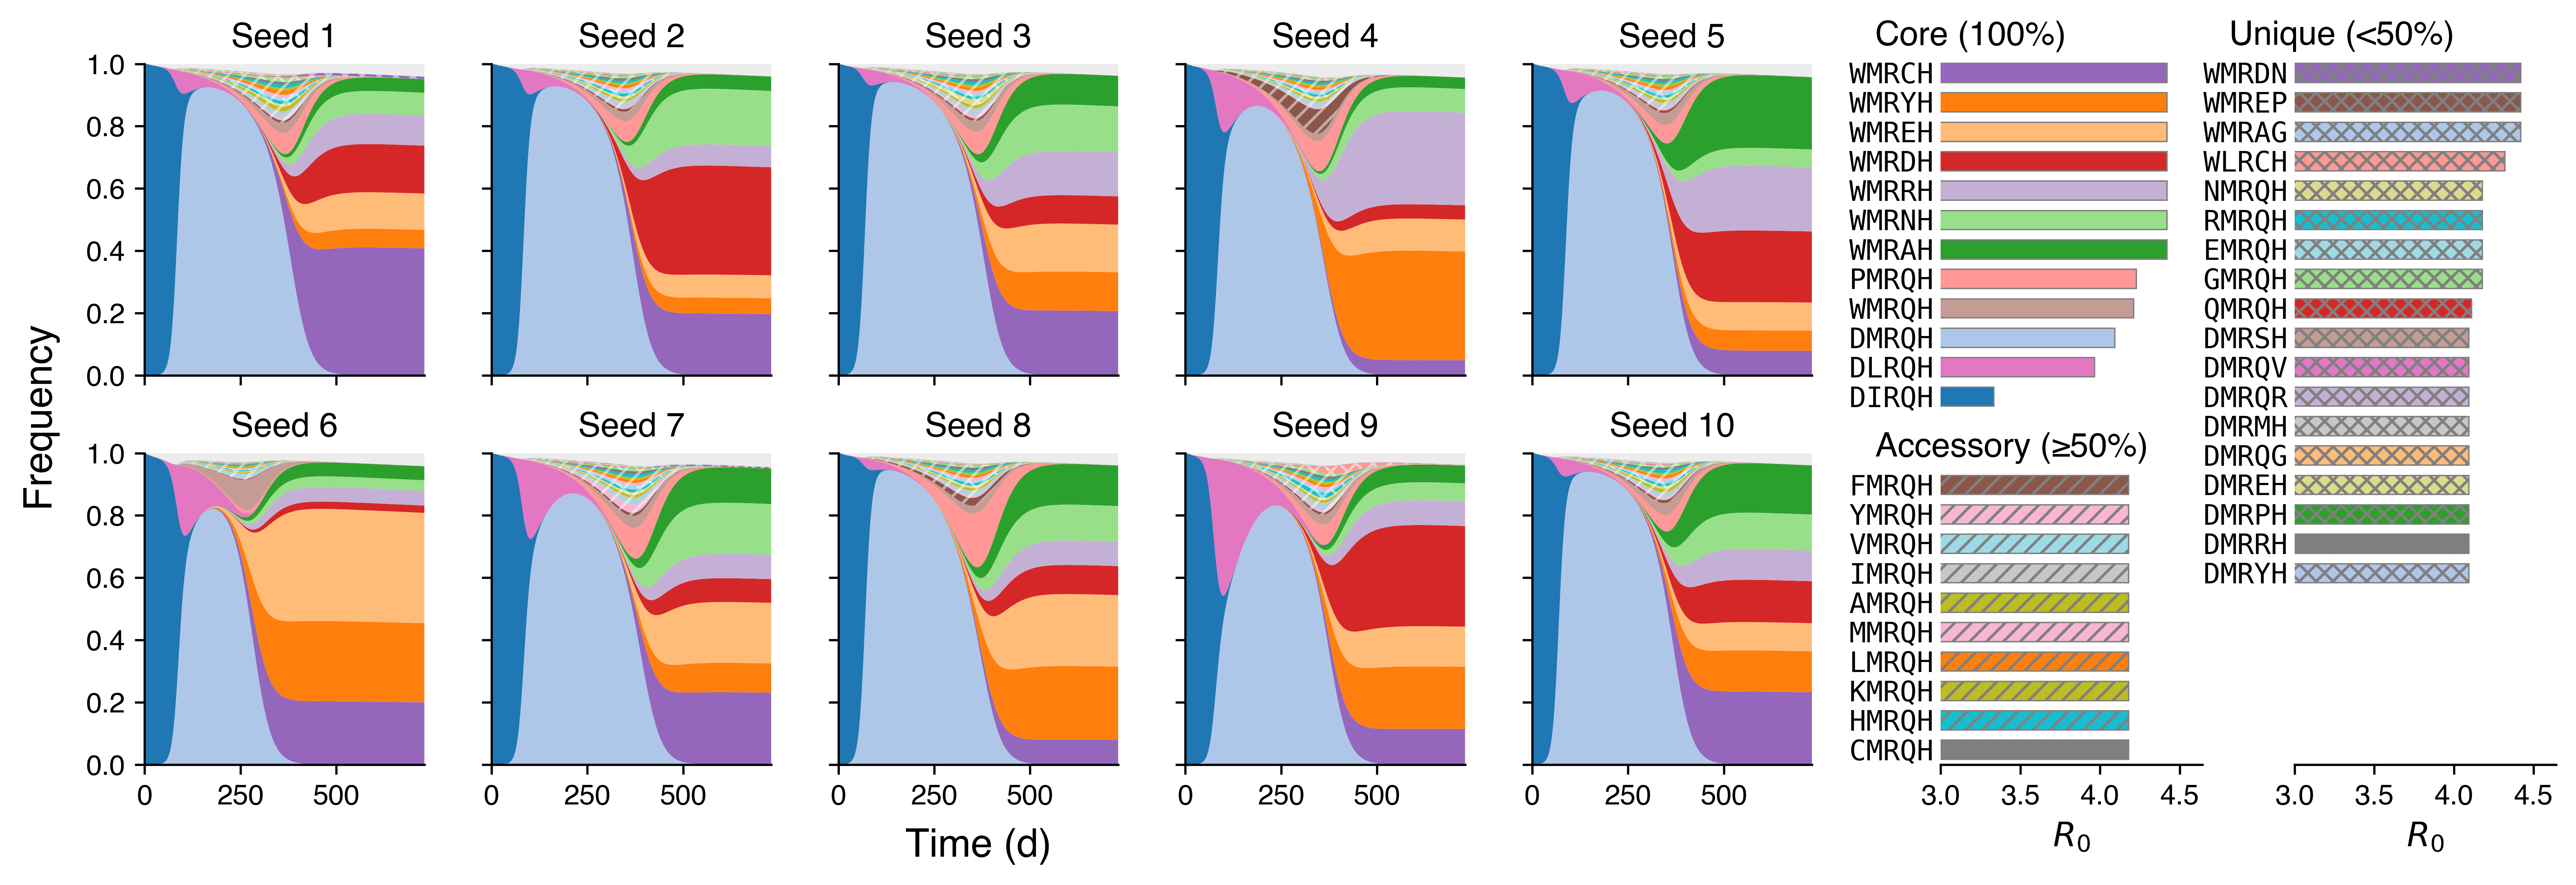

In [10]:
def draw_summary_legend(legend_ax, sequences, color_map, classification, r0_map, acc_threshold=0.5):
    """Helper to draw a legend with sequences and their classification (core/accessory/unique) and labeled by R0."""
    legend_ax.axis("off")
    acc_pct = int(acc_threshold * 100)

    def by_r0(s):
        r0 = r0_map.get(s)
        return r0 if r0 is not None else float("-inf")

    core = sorted([s for s in sequences if classification.get(s) == "core"], key=by_r0, reverse=True)
    acc = sorted([s for s in sequences if classification.get(s) == "accessory"], key=by_r0, reverse=True)
    uniq = sorted([s for s in sequences if classification.get(s) == "unique"], key=by_r0, reverse=True)

    left_items = []
    left_items.append(("header", "Core (100%)"))
    left_items.extend(("seq", s) for s in core)

    if acc:
        left_items.append(("spacer",))
        left_items.append(("header", f"Accessory (≥{acc_pct}%)"))
        left_items.extend(("seq", s) for s in acc)

    right_items = []
    if uniq:
        right_items.append(("header", f"Unique (<{acc_pct}%)"))
        right_items.extend(("seq", s) for s in uniq)

    while len(right_items) < len(left_items):
        right_items.append(("spacer",))

    COL_GAP = 0.15
    COL_W = (1.0 - COL_GAP) / 2.0
    
    all_vals = [by_r0(s) for s in sequences if by_r0(s) > -np.inf]
    r0_max = max(all_vals) * 1.05 if all_vals else 1.0

    def draw_column(items, x0):
        ax = legend_ax.inset_axes([x0+0.1, 0.0, COL_W, 1.05], transform=legend_ax.transAxes)
        ax.set_xlim(3, r0_max)
        ax.set_ylim(len(items) - 0.5, -0.5)
        ax.set_yticks([])
        ax.set_xlabel(f"$R_0$", fontsize=12)
        ax.set_xticks([3, 3.5, 4, 4.5])
        ax.tick_params(axis="x", labelsize=10)

        for spine in ("left", "right", "top"):
            ax.spines[spine].set_visible(False)
        
        for row, item in enumerate(items):
            kind = item[0]

            if kind == "spacer":
                continue
            y = row
            if kind == "header":
                ax.text(-0.25, y-0.25, item[1], transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=12, fontweight="bold")
                continue

            s = item[1]
            color = color_map.get(s, "#ebebeb")
            cat = classification.get(s, "core")
            hatch = ""
            if cat == "accessory":
                hatch = "////"
            elif cat == "unique":
                hatch = "xxxx"
            label = rf"$\mathtt{{{s}}}$"
            
            ax.text(-0.35, y+0.1, label, transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=10)
            val = r0_map.get(s, np.nan)
            ax.barh(y, float(val), height=0.65, left=0.0, color=color, edgecolor="grey", linewidth=0.5, hatch=hatch)

    draw_column(left_items, 0.0)
    draw_column(right_items, COL_W + COL_GAP)

totals_dfs = []
topk_dfs = []

def reconcile_color_map(color_map, reference_color_map):
    """Override colors to match reference_color_map for any sequence present in both (to match Fig. S1 colors with Fig. 1)"""
    final = dict(color_map)
    color_to_seq = {c: s for s, c in final.items()}
    overrides = {s: c for s, c in reference_color_map.items() if s in final}

    for seq, target_color in overrides.items():
        current_color = final[seq]
        if current_color == target_color:
            continue
        rep = color_to_seq.get(target_color)

        final[seq] = target_color
        color_to_seq[target_color] = seq

        if rep is not None:
            final[rep] = current_color
            color_to_seq[current_color] = rep
        else:
            color_to_seq.pop(current_color, None)

    return final

for i, s in enumerate(seeds):
    totals_path = totals_by_seed[s]
    totals_dfs.append(pd.read_csv(totals_path))
    topk_path = topk_by_seed[s]
    topk_dfs.append(pd.read_csv(topk_path))

global_topk = compute_global_topk(topk_dfs, top_k=40)
classification = classify_sequences(topk_dfs, global_topk)
colmap = build_color_map(global_topk)
colmap = reconcile_color_map(colmap, ex_colmap)

fig = plt.figure(figsize=(15, 4.5))
gs = fig.add_gridspec(2, 6, width_ratios=[1,1,1,1,1,2.2], hspace=0.25)
axes = np.array([[fig.add_subplot(gs[0, i]) for i in range(5)], [fig.add_subplot(gs[1, i]) for i in range(5)]])
legend_ax = fig.add_subplot(gs[:, 5])
legend_ax.axis("off")

for i, (tot, topk) in enumerate(zip(totals_dfs, topk_dfs)):
    r, c = divmod(i, 5)
    ax = axes[r, c]
    stacked_frequency_plot(ax, tot, topk, global_topk, colmap, classification, x_max=730)
    ax.set_title(f"Seed {seeds[i]}", fontsize=12)
    ax.set_ylabel("")

    if c != 0:
        ax.set_yticklabels([])

    if r != 1:
        ax.set_xticklabels([])

left = axes[0, 0].get_position().x0
right = axes[0, -1].get_position().x1
bottom = axes[1, 0].get_position().y0
top = axes[0, 0].get_position().y1

x_center = (left + right) / 2
y_center = (bottom + top) / 2

fig.text(x_center, bottom - 0.09, "Time (d)", ha="center", va="center", fontsize=14)
fig.text(left - 0.035, y_center, "Frequency", ha="center", va="center", rotation="vertical", fontsize=14)

df = ddG_dataframe.set_index("sequence")
r0_map = {s: r0_fun(ddg_receptor=df.loc[s, "ddG"], ddg_ab=df.loc[s, "ddG_Ab"], Ab_dose=0, p=params) for s in global_topk}
draw_summary_legend(legend_ax, global_topk, colmap, classification, r0_map)

plt.savefig('FigS1.png', dpi=600, bbox_inches='tight')